## Welcome to the tutorial for the **Hulkshare Recommendation Algorithm Challenge**
<figure>
<center>
<img src = "https://drive.google.com/uc?export=view&id=15Rj1BSmQWOgUPSCDyosu4gOGH1n6IDop" width = "500"/>

Table of contents:

1. [Introduction](#Introduction)
2. [Dataset overview](#Dataset)
3. [Data exploratory analysis](#Exploration)
4. [Feature engineering](#Engineering)
5. [Baseline model](#Model)
6. [Preparing a submission file](#Submit)
7. [Tips on improving model performance](#Suggestions)


<a name = "Introduction"></a>
## 1. Introduction

The objective of this competition is to determine if a listener enjoyed a song, without external information. You will need to develop a machine learning algorithm to predict whether someone enjoyed a song using the frames of a song, duration of the song and the viewing pattern.

Frames are often associated with videos but they can be used for songs. 

In [1]:
# Importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from lightgbm import LGBMRegressor
from joblib import Parallel, delayed
from functools import reduce
from pprint import pprint
import ast
import requests
import gc

pd.set_option('max_colwidth', None)
import warnings
warnings.filterwarnings('ignore')

Downlaod data directly from zindi to colab
 - [Link](https://github.com/sayedmohamedscu/Zindi_colab) to a tutorial explaining on how to download competition files directly from Zindi to colab

In [2]:
# # Function to download data directly from zindi
# def zindi_data_downloader(url, auth_token, save_file_path):
#   data_request = requests.post(url, data = auth_token,stream=True)

#   handle = open(save_file_path, "wb")
#   for chunk in data_request.iter_content(chunk_size=512):
#       if chunk:  # filter out keep-alive new chunks
#           handle.write(chunk)
#   handle.close()

# train_details = {'url':,
#                  'save_path_path': 'train.csv'}

# test_details = {'url':,
#                  'save_path_path': 'test.csv'}

# SampleSubmission_details = {'url':,
#                             'save_path_path': 'SampleSubmission.csv'}

# videos_on_repeat = {'url':,
#                     'save_path_path': 'videos_on_repeat.csv'}

# frames = {'url':,
#           'save_path_path': 'frames.csv'}

# test_frames = {'test_frames1': {'url':,
#                                 'save_path_path': 'frames.csv'},
#                'test_frames2': {'url':,
#                                 'save_path_path': 'frames.csv'},
#                'test_frames3': {'url':,
#                                 'save_path_path': 'frames.csv'},
#                'test_frames4': {'url':,
#                                 'save_path_path': 'frames.csv'},
#                'test_frames5': {'url':,
#                                 'save_path_path': 'frames.csv'}}

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# Loading files
path = '/content/drive/Shareddrives/ZINDI/4. Zindi Business Development/4.1 Customers (Hosts)/Hulkshare/3. Competitions/Competition #1 - likes2views/2. Data/2. Processed/Frontend/'
train = pd.read_csv(path + 'train.csv')
test = pd.read_csv(path + 'test.csv')
sample_submission = pd.read_csv(path + 'SampleSubmission.csv')
videos_on_repeat = pd.read_csv(path + 'videos_watched_on_repeat.csv')

# Load video frames data
frames = pd.read_csv(path + 'train_frames4.csv')

<a name = 'Dataset'></a>
## 2. Data overview

The data for this competition includes listening patterns of different users listening to songs

The frames given in this competition are from the most recent 6 months. 

Some important things to note:
 - *When a viewer/user logs onto the platform, they enter a session. In this session the viewer/user can watch different videos*
 - *They can also listen to the same song multiple times in the same way or differently.*


In [8]:
# Preview train dataset
train.head(2)

,vid_id,num_sessions,session_ids_and_duration,target
0,ID_N5PFIWFKWJ,10,"[{'d3ae981884a18ee794df8ff85335e96d4cca975f': 699}, {'141bdf8baf93933faa3b4ff000f76d1360786221': 1056}, {'8613da2cd754208659b06f69b7f57fa32482696f': 40}, {'29a13fef2fa62704e534a29fe9fdc03cebfe65ed': 94}, {'1f04a3240a2b744cf2c902314d70f2d45581b349': 456}, {'998db2b1e5e58c40bbf9a720ee8162b7387a84c3': 15}, {'eda3b89874d03e4db8ebe87ffc7692e1c25c6d07': 446}, {'ec6ec120f51a64b4c48ebc43071cd9d053350d8f': 743}, {'2a1f330915c689b1666447d75ee23ef82487ce32': 1}, {'947d16eb53ab92df9a1bf6a2e525ddab3a23e6af': 84}]",0.001742
1,ID_99OSBTT4R8,7,"[{'909aa08e09574647040a86320daeb6f53603a964': 30}, {'ba1f42156e72446f56106861ad8bc26458962854': 35}, {'1bd966bd9b6b2b3f3700ced0f31e3def241fa0ca': 192}, {'db8b6f6c85e6a0077df48c1db05a646ba9fcd4a4': 19}, {'850eb84f63af7f3b8c969eed6e46f1a791e644b4': 51}, {'c868f2994513c4ba46039955fe15c32b28a91873': 410}, {'67c0b1e10113977dbf142bbd439c92f6141961c1': 77}]",0.001714


In [9]:
# Preview test dataset
test.head(2)

,vid_id,num_sessions,session_ids_and_duration
0,ID_XOSNMS1ZMQ,5,"[{'12989b3fe0756a8781b272e6453c72cebf885099': 139}, {'fbf37072136ef96ed9c63b0e01e101cd10991b5a': 74}, {'b95c2c16af3c248fb14cdc22dbd25ec213ff6e2b': 215}, {'c2f618c0fd8440351e2df2dccdc7cf0a3b82690f': 170}, {'89e2a4fd1e76cc464d96c90a713ebf15de6fc2c6': 146}]"
1,ID_YRXR4XN6G3,18,"[{'01f8f3839fcf847b70655f9c0daee6601af9b69f': 701}, {'187071c41a7eeb4497ddaf563ab218e529f026ba': 414}, {'936a9775464ab7aa9ec3e8297016bcacb639282e': 45}, {'dbff79e3d9e8bd051738cb137dd6d327a6cc3db3': 39}, {'e3ff2d1c91220067588969e62b79ebdda55a54f9': 1535}, {'bf8b71c8305d02ecf9451f52a5eff7f5726a1f92': 996}, {'5e1b59eca5c58b4ad8eaa4d007e0e9b16e1f09e1': 403}, {'a0c41bc4fd64c823556f889be70ea20b4c2dddc9': 284}, {'f174b725a5144cb0c42dda8c852b4076dab4792c': 755}, {'746bea1885ef12ef41392d5ac5fa802564ab3cdc': 437}, {'c6bc1cd0d727354ce4ee67f771872befe57647b8': 163}, {'f3cc539d939c1436a80c3ac5ed75256ffa8afd09': 28}, {'e4d00b74e4244fdbdbf27d85a177d30a699445ec': 553}, {'224485e5be3f3e1e26c4b233aaeb8112a14ad2c8': 274}, {'90ae7828fb5386233e6f018a47d4efee74aba672': 1068}, {'10bbbdbc24774c78b9dea23ed848401b46dc191c': 475}, {'c01afdd54d65ec7af834c0aa530a292469f42462': 4}, {'12b09cf6d3c9a97932d6a50d82ff864ea0c36806': 1353}]"


In [10]:
# Preview sample submission
sample_submission.head()

,vid_id,target
0,ID_XOSNMS1ZMQ,0
1,ID_YRXR4XN6G3,0
2,ID_GVRGM8REV5,0
3,ID_QULJLKXTJ2,0
4,ID_FF8S81W6P0,0


In [11]:
# Preview the frames dataset
frames.head()

,vid_id,frame,vidTime,timelineRatio,session_id,session_duration
0,ID_OINWKK67YE,0.000000,0.000000,0.000000,9a190bfc36eef64574382ce32ffee57e3c509491,2212
1,ID_OINWKK67YE,66.426426,2.214214,0.001207,9a190bfc36eef64574382ce32ffee57e3c509491,2212
2,ID_OINWKK67YE,132.852853,4.428428,0.002413,9a190bfc36eef64574382ce32ffee57e3c509491,2212
3,ID_OINWKK67YE,199.279279,6.642643,0.003620,9a190bfc36eef64574382ce32ffee57e3c509491,2212
4,ID_OINWKK67YE,265.705706,8.856857,0.004827,9a190bfc36eef64574382ce32ffee57e3c509491,2212


In [12]:
# Shape of train and test sets
train.shape, test.shape, sample_submission.shape

((14630, 4), (7867, 3), (7867, 2))

<a name = "Exploration"></a>
## 3. Exploratory data analysis

In [13]:
# Train dataset description
train.describe()

,num_sessions,target
count,14630.000000,14630.000000
mean,12.876145,0.001875
std,16.363818,0.001221
min,5.000000,0.000028
25%,6.000000,0.001072
50%,8.000000,0.001613
75%,13.000000,0.002359
max,191.000000,0.021043


 - There are 14630 training samples in the train set
 - Minimum number of number of sessions/listening patterns per song is 5
 - Majority of songs have around 12 different listening patterns
 - The likes to views ratio i.e the target has a minimum of 0.000028 and a maximum of 0.021043

In [14]:
# Test dataset description
test.describe()

,num_sessions
count,7867.000000
mean,12.773993
std,16.101012
min,5.000000
25%,6.000000
50%,7.000000
75%,13.000000
max,188.000000


- The number of sessions/ viewing patterns in train and test set are fairly balanced

In [15]:
# Check for missing values
train.isnull().sum().any(), test.isnull().sum().any()

(False, False)

Lets explore one of the watched videos

In [16]:
# Lets explore one video with 5 number of sessions/ viewing patterns
train[train.vid_id  == 'ID_AHV7WCWKJM']

,vid_id,num_sessions,session_ids_and_duration,target
12375,ID_AHV7WCWKJM,5,"[{'0dd29f733b643ede5a6f36aa592ce73da42db46c': 1064}, {'0c38a0bbddd69c76e5c942cb0befa4d19d22abc1': 548}, {'1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f': 244}, {'494717b2725fad99e78d8ab96c6a2b3a1796b8b0': 292}, {'9f515a67f49650f3699b399c461b5646131d228c': 435}]",0.000943


**Frames data analysis**

What is a frame?
 - [Frame rates](https://wave.video/blog/video-frame-rate/#:~:text=standard%20frame%20rates.-,Frame%20rates%20refer%20to%20the%20number%20of%20times%20images%20are%20flashed%20on%20a%20screen%20during%20a%20given%20second%20to%20give%20the%20illusion%20of%20movement.,-Traditional%20film%2C%20such) refer to the number of times images are flashed on a screen during a given second to give the illusion of movement

The idea of frames has been used for songs by Hulkshare. 

In [17]:
# Getting the frames data for vid_id "ID_AHV7WCWKJM"
frames_df = frames[frames.vid_id == 'ID_AHV7WCWKJM'].reset_index(drop = True)
frames_df.head()

,vid_id,frame,vidTime,timelineRatio,session_id,session_duration
0,ID_AHV7WCWKJM,0.000000,0.000000,0.00000,0dd29f733b643ede5a6f36aa592ce73da42db46c,1064
1,ID_AHV7WCWKJM,31.951952,1.065065,0.00194,0dd29f733b643ede5a6f36aa592ce73da42db46c,1064
2,ID_AHV7WCWKJM,63.903904,2.130130,0.00388,0dd29f733b643ede5a6f36aa592ce73da42db46c,1064
3,ID_AHV7WCWKJM,95.855856,3.195195,0.00582,0dd29f733b643ede5a6f36aa592ce73da42db46c,1064
4,ID_AHV7WCWKJM,127.807808,4.260260,0.00776,0dd29f733b643ede5a6f36aa592ce73da42db46c,1064


In [18]:
# There are 1000 frames per song
frames_df.shape

(5000, 6)

In [19]:
# Confirming that vid_id ID_AHV7WCWKJM has 5 viewing patterns 
pprint(frames_df.session_id.nunique()), pprint(frames_df.session_id.unique())

5
array(['0dd29f733b643ede5a6f36aa592ce73da42db46c',
       '0c38a0bbddd69c76e5c942cb0befa4d19d22abc1',
       '1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f',
       '494717b2725fad99e78d8ab96c6a2b3a1796b8b0',
       '9f515a67f49650f3699b399c461b5646131d228c'], dtype=object)


(None, None)

**Listening mechanics**
- If there is a steady increase in the frames, then the user is listening to the song normally
- If it is still, then the user paused the song.
- If there is a sudden spike in the frames then the user is skipping forward.
- If there is a sudden drop then the user is skipping backwards.
- TimelineRatio is vidTime / video duration.

**Ploting frames**

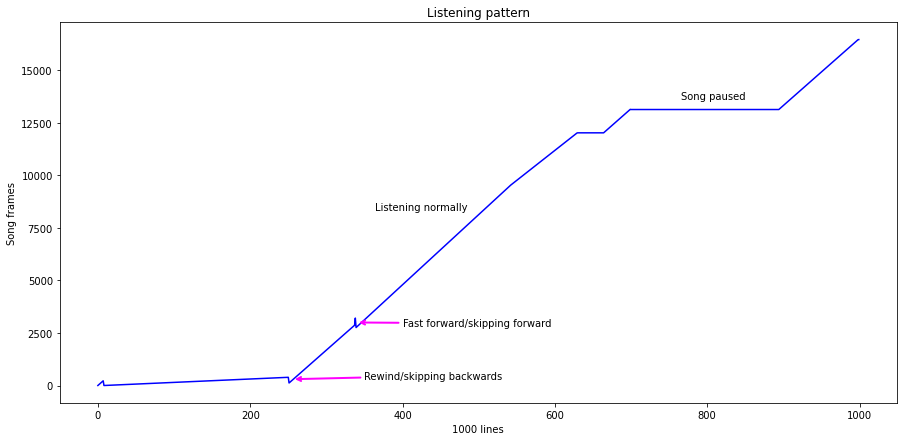

In [20]:
# Plotting session id 0dd29f733b643ede5a6f36aa592ce73da42db46c for vid_id ID_AHV7WCWKJM
frames_id1 = frames_df[(frames_df.session_id == '0dd29f733b643ede5a6f36aa592ce73da42db46c') & (frames_df.session_duration == 1064)]
plt.figure(figsize = (15, 7))
plt.plot(range(1000), frames_id1.frame, color = 'blue')
plt.xlabel('1000 lines') # Each video is cut into 1000 lines
plt.ylabel('Song frames')
plt.title('Listening pattern')
plt.annotate('Listening normally', xy = (485, 8750), horizontalalignment='right', verticalalignment='top')
plt.annotate('Song paused', xy = (850, 14000), horizontalalignment='right', verticalalignment='top')
plt.annotate('Fast forward/skipping forward', xy = (340, 3000), xytext=(400, 3200), horizontalalignment='left', verticalalignment='top',
             arrowprops=dict(arrowstyle='->',lw=2, color = 'magenta'))
plt.annotate('Rewind/skipping backwards', xy = (256, 300), xytext=(350, 700), horizontalalignment='left', verticalalignment='top',
             arrowprops=dict(arrowstyle='->',lw=2, color = 'magenta'))
plt.show()

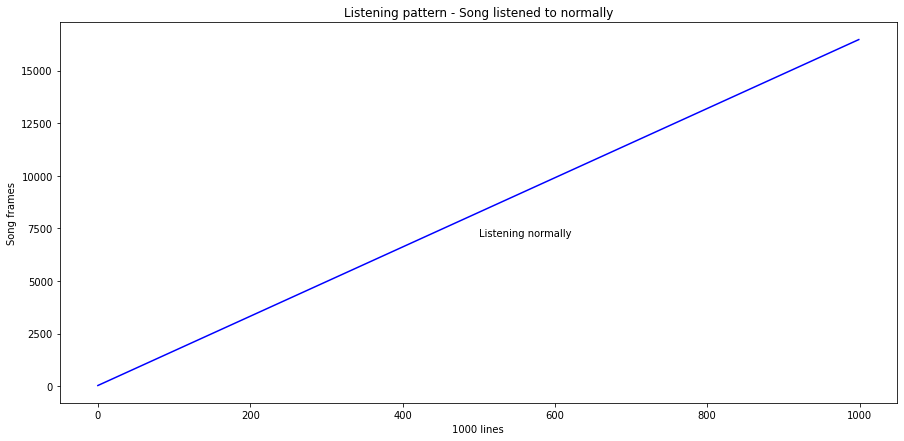

In [21]:
# Plotting session id 0c38a0bbddd69c76e5c942cb0befa4d19d22abc1 for vid_id ID_AHV7WCWKJM
frames_id2 = frames_df[(frames_df.session_id == '0c38a0bbddd69c76e5c942cb0befa4d19d22abc1') & (frames_df.session_duration == 548)]
plt.figure(figsize = (15, 7))
plt.plot(range(1000), frames_id2.frame, color = 'blue')
plt.xlabel('1000 lines') # Each video is cut into 1000 lines
plt.ylabel('Song frames')
plt.title('Listening pattern - Song listened to normally')
plt.annotate('Listening normally', xy = (500, 7500), verticalalignment='top')
plt.show()

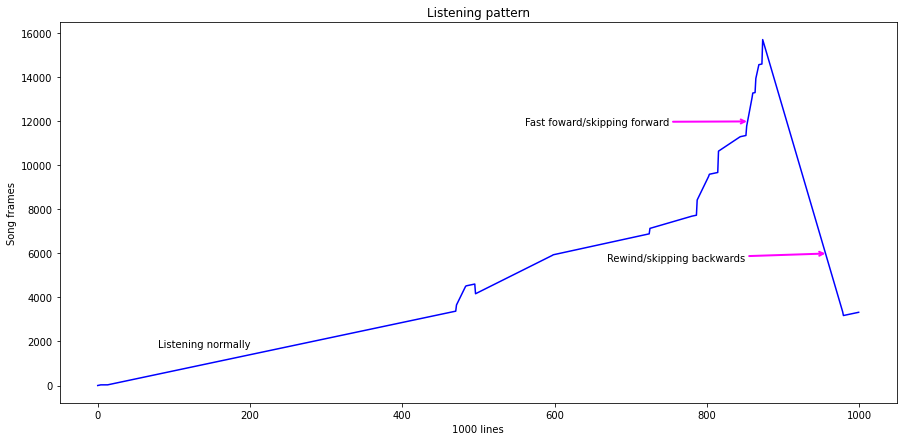

In [22]:
# Plotting session id 0c38a0bbddd69c76e5c942cb0befa4d19d22abc1 for vid_id ID_AHV7WCWKJM
frames_id3 = frames_df[(frames_df.session_id == '1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f') & (frames_df.session_duration == 244)]
plt.figure(figsize = (15, 7))
plt.plot(range(1000), frames_id3.frame, color = 'blue')
plt.xlabel('1000 lines') # Each video is cut into 1000 lines
plt.ylabel('Song frames')
plt.title('Listening pattern')
plt.annotate('Listening normally', xy = (200, 2100), horizontalalignment='right', verticalalignment='top')
plt.annotate('Fast foward/skipping forward', xy = (855, 12000), xytext=(750, 12200), horizontalalignment='right', verticalalignment='top',
             arrowprops=dict(arrowstyle='->',lw=2, color = 'magenta'))
plt.annotate('Rewind/skipping backwards', xy = (958, 6000), xytext=(850, 6000), horizontalalignment='right', verticalalignment='top',
             arrowprops=dict(arrowstyle='->',lw=2, color = 'magenta'))
plt.show()

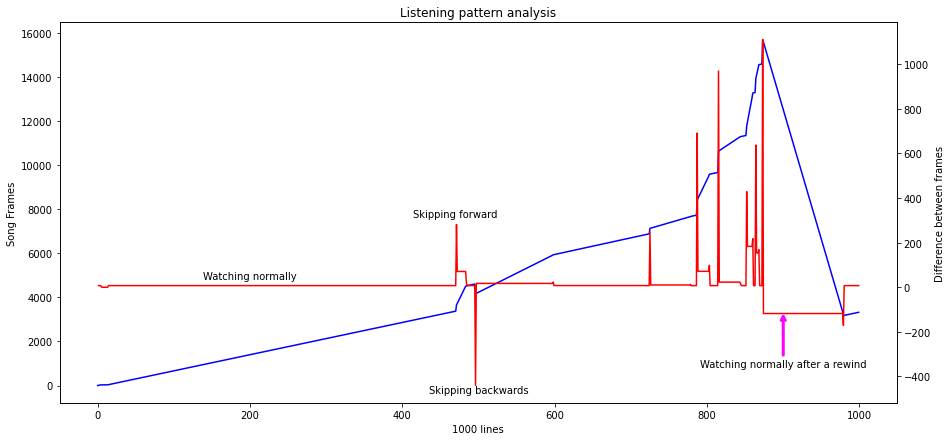

In [23]:
# Better way of visualising skipping forward or backwards
# This can be achieved by finding the difference in the frames
fig, ax = plt.subplots(figsize = (15, 7))
ax.plot(range(1000), frames_id3.frame, color = 'blue')
ax.set_xlabel('1000 lines')
ax.set_ylabel('Song Frames')
ax2=ax.twinx()
ax2.plot(range(1000), frames_id3.frame.diff(), color = 'red')
ax2.set_ylabel('Difference between frames')
plt.title('Listening pattern analysis')
ax.annotate('Watching normally', xy = (200, 5200), horizontalalignment='center', verticalalignment='top')
ax.annotate('Skipping forward', xy = (470, 8000), horizontalalignment='center', verticalalignment='top')
ax.annotate('Skipping backwards', xy = (500, 0), horizontalalignment='center', verticalalignment='top')
ax.annotate('Watching normally after a rewind', xy = (900, 3380), xytext=(900, 1200),horizontalalignment='center', verticalalignment='top',
             arrowprops=dict(arrowstyle='->',lw=3, color = 'magenta'))
plt.show()

- Visualing the difference in frames will help in clearly distinguish fast forwards, rewinds, pausing and normal watching.

<a name = "Engineering"></a>
## 4. Feature engineering
Some of the features we can engineer
 1. [Video duration](#Duration)
 2. [Ratio of time taken to watch a video to video length](#Time_taken_ratio)
 4. [Number of times a user forwarded, rewidend, paused, watched normally...](#Forwards_rewinds)
 5. [Aggregates of the frames difference per viewing pattern](#Aggregates)
 6. [Flag to capture information whether a video was watched on repeat](#Repeat_flag)

<a name = "Duration"></a>
### 1. Video duration
 - TimelineRatio is vidtime / video duration 

In [24]:
# Preview the frames_id3 dataframe
frames_id3.head()

,vid_id,frame,vidTime,timelineRatio,session_id,session_duration
2000,ID_AHV7WCWKJM,0.000000,0.000000,0.000000,1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f,244
2001,ID_AHV7WCWKJM,7.327327,0.244244,0.000445,1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f,244
2002,ID_AHV7WCWKJM,14.654655,0.488488,0.000890,1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f,244
2003,ID_AHV7WCWKJM,21.981982,0.732733,0.001335,1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f,244
2004,ID_AHV7WCWKJM,29.309309,0.976977,0.001780,1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f,244


In [25]:
# video duaration is vidTime / timelineRatio
video_duration = round(frames_id3.vidTime.sum() / frames_id3.timelineRatio.sum(), 2)
frames_id3['video_duration'] = video_duration
video_duration

549.0

<a name = "Time_taken_ratio"></a>
### 2. Ratio of time taken to listen to a song to song length

In [26]:
train[train.vid_id == 'ID_AHV7WCWKJM']

,vid_id,num_sessions,session_ids_and_duration,target
12375,ID_AHV7WCWKJM,5,"[{'0dd29f733b643ede5a6f36aa592ce73da42db46c': 1064}, {'0c38a0bbddd69c76e5c942cb0befa4d19d22abc1': 548}, {'1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f': 244}, {'494717b2725fad99e78d8ab96c6a2b3a1796b8b0': 292}, {'9f515a67f49650f3699b399c461b5646131d228c': 435}]",0.000943


In [27]:
# Getting the session ids and durations
ast.literal_eval(train[train.vid_id == 'ID_AHV7WCWKJM'].session_ids_and_duration.values[0])

[{'0dd29f733b643ede5a6f36aa592ce73da42db46c': 1064},
 {'0c38a0bbddd69c76e5c942cb0befa4d19d22abc1': 548},
 {'1234c5cd900e5d964c3d4c3f5bcb70a2985aad6f': 244},
 {'494717b2725fad99e78d8ab96c6a2b3a1796b8b0': 292},
 {'9f515a67f49650f3699b399c461b5646131d228c': 435}]

In [28]:
# Getting the average duration
sess_durs = []
for sess_dur in ast.literal_eval(train[train.vid_id == 'ID_AHV7WCWKJM'].session_ids_and_duration.values[0]):
  sess_durs.append(list(sess_dur.values())[0])

avg_sess_dur = np.mean(sess_durs)
sess_durs, avg_sess_dur

([1064, 548, 244, 292, 435], 516.6)

In [29]:
# sess_duration_to_video_duration calculation
sess_duration_to_video_duration = avg_sess_dur / video_duration * 100
sess_duration_to_video_duration

94.09836065573771

<a name = "Forwards_rewinds"></a>
### 3. Number of times a user forwarded, rewinded, paused, listened normally...

Using the findpeaks library we can find the number of forwards and rewinds in a video

This library [findpeaks](https://pypi.org/project/findpeaks/) aims to detect peaks in a 1-dimensional vector and 2-dimensional arrays (images) without making any assumption on the peak shape or baseline noise. To make sure that peaks can be detected across global and local heights, and in noisy data, multiple pre-processing and denoising methods are implemented.

In [30]:
# Install library
!pip install -qq findpeaks

     |████████████████████████████████| 45 kB 1.8 MB/s 


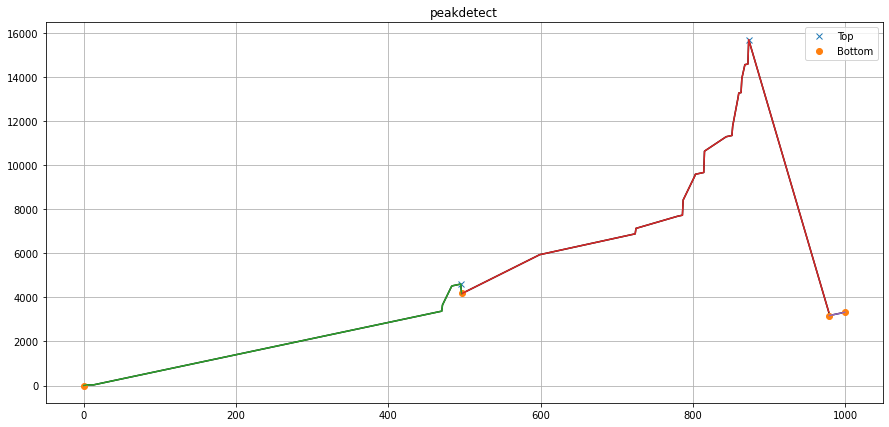

In [31]:
# Import library
from findpeaks import findpeaks

# Initialize
fp = findpeaks(lookahead=1, verbose = 0)
results = fp.fit(frames_id3.frame)
# Plot
fp.plot(figsize = (15, 7))
plt.show()

In [32]:
# Previewing the number of peaks/forwards and valleys/rewinds
peaks_df = fp.peaks1d(frames_id3.frame)['df']
peaks_df.head()

,x,y,labx,valley,peak
0,0,0.000000,1.0,True,False
1,1,7.327327,1.0,False,False
2,2,14.654655,1.0,False,False
3,3,21.981982,1.0,False,False
4,4,29.309309,1.0,False,False


In [33]:
# Calculating the number of peaks/forwards and valleys/rewinds
forwards = peaks_df.peak.sum()
rewinds = peaks_df.valley.sum()
forwards, rewinds

(2, 4)

 <a name = "Aggregates"></a>
 ### 4. Aggregates of the frames difference per listening pattern

In [34]:
#Aggregates of frames diff
frames_diff = frames_id3.frame.diff()
frames_diff.min(), frames_diff.max(), frames_diff.sum(), frames_diff.mean(), frames_diff.std()

(-440.60060060060005,
 1110.6906906910008,
 3326.5465465465004,
 3.3298764229694697,
 75.35840523528243)

<a name = "Repeat_flag"></a>
### 5. Flag to capture information whether a song was listened to on repeat

In [35]:
# Preview songs listened to on repeat
videos_on_repeat.head()

,vid_id,session_id,session_duration
0,ID_59DJBN2K1T,1e35fc1ae3f61c329a3803dd2e897d2e93017cb7,1058
1,ID_VOUELDAP5J,cdae9441190cdbe0f5c8c91ed63f9fad2c6e4388,130
2,ID_TWC05Y7H2K,20495ef25fda6a1cb9a8ed81793b69f9302a0b40,221
3,ID_9I1YPQ9M9B,90bd7022bce2a68206dae60a48f87e2434471424,248
4,ID_ARA0DD8MDZ,4b8096a1dc4eb9120907cb8c9b5b88d2b4e92bb1,242


In [36]:
# 1 if its true else 0
1 if 'ID_AHV7WCWKJM' in videos_on_repeat.vid_id else 0

0

### Train set feature engineering
 - A sample of 1000 songs has been used for training the model
 - Two listening patterns have been used in training. This is for quick prototyping and experimentations

In [37]:
# Get a sample of 1000 songs to be used in training a model
train_sample_ids = list(set(frames.vid_id.unique().tolist()).intersection(set(train.vid_id.tolist())))[:1000]

# Filter training data
train_sample = train[train.vid_id.isin(train_sample_ids)].reset_index(drop = True)
train_sample.head()

,vid_id,num_sessions,session_ids_and_duration,target
0,ID_6DDGSMS1F4,5,"[{'9fa1744d447c19ced14657b877a119705fff83a2': 53}, {'0f9540d3ab18d9c37663ef76fadbf7da0958ee1d': 77}, {'8c4b6a651c61e113fed9e7c4f3874e3ab41a8568': 11}, {'c4591f9d1d607db0122c7bf1a49c78a0fa56bbcd': 12}, {'5b122fa6ddc6b849bbf9feb6fd21ab90f8e234ad': 55}]",0.001927
1,ID_A3ZYEOZR1S,9,"[{'a5dd73aa35d9a115182a55171f86918f32f7a582': 214}, {'f732e0e0a60099c7a2c86380cd55b8252b7da3e7': 179}, {'1eb890a39d86cab35d37ed977ca78e63e933df41': 3}, {'3587d7a0b517a76e19e360e17a68cf20ca1bae08': 294}, {'d748fb7f6f3c1571d025124ada1dddd3d89af748': 86}, {'2e263f36ca36f3500d4fc8d9f8a91371f372968b': 232}, {'00d1e14e01e03f078775d0292933edb251dc948e': 77}, {'16842d6b2ad61854dfc4d5782eb6deef800da842': 37}, {'113f46fa9d861897b9bf584b18df8eff75651b7a': 45}]",0.003495
2,ID_IAR2KO1SL3,24,"[{'076513ebc6818fa31accad9d7c25c01056598773': 47}, {'b0a743beea72eb25c31710cca75c7dc4bfd0f6f9': 291}, {'c622fdb4ecd519449502a662dde3a4dbd7eb20d1': 158}, {'08b4a92f551831551296da124bcbd52bdb04e5f2': 3}, {'7e9aa99e1cdb15f3867699d55f33c6eaccbe2a24': 14}, {'107957ab730246cb2db0eec2696a6e734c08af98': 82}, {'dfbbf53304c5aa3a3b32fc658761b5b1f7cc958c': 28}, {'802cda817fd446e82db0e835ef9fbb8575db0626': 647}, {'134b61a794328cd03b4117a1534745c804f9f200': 30}, {'6ea31e444e74123e66d9c5c402a8c1df378c1898': 4}, {'59257c171d4ab1b71d5b44e82ac6df51d0937724': 91}, {'e0b2ab0dd6204304452878df5c57b9245c0525d5': 1579}, {'a2ba59c7960fe8999bc801bf918a3488a3ef31ac': 123}, {'bf9e144ea5853559f99fe1aea0d34750b4213d6e': 717}, {'dd0bc335cba6c0815741271356d2adae9cbfa70e': 813}, {'bb2bfb9145e20b1fb5d390e07a4d87e24d5c6ae3': 219}, {'27dc80a155fe8cd26211b147b90f782709f84f88': 106}, {'9bfc710e1baa313cdfedae3d6c3df6cbdf23d2a8': 9}, {'570b732847015689844c458e77fe04199f6e056c': 188}, {'b8423190757eb913a2fb7b8785839143035dcf60': 155}, {'9f08a04e060d606de1fc922af5645755e8949fa8': 109}, {'1dfcc75e7b3364b9ab61d86d0d713fec4fd94b99': 31}, {'97e3ed459aa719ca93003429674b2880ad07e1a0': 19}, {'c52c07170c1f48ed48392c381019246ea9a74f20': 88}]",0.001715
3,ID_HJ8GW3YL91,8,"[{'34420a9b7d5e2754e6edb7a0149ce38e9d5b591b': 21}, {'c5f5283320361a027bed7164a465af71cd540fe6': 33}, {'60b2063f6201361dd0cd75cad2c47ee4b95786c3': 356}, {'11d46165478b84492df9a946eebf3eb967c054ab': 21}, {'154b843237a8f25a971e119b9be8094a7e565fb2': 94}, {'004a58f4d4b2267f618543e3bd3626a604f73f11': 21}, {'d2e0d59173cc36d912b39ad6a4b8464b769e27fb': 16}, {'431b94637dc371577f2509a3e9575ff98289adee': 21}]",0.002044
4,ID_RT0HXO71PD,7,"[{'ee95b0f41953bae5d0911d7c75b01442017a2c08': 326}, {'ba1fded4dda99334d364fa295f6d12b97a7ff3f5': 69}, {'bcbb4d44aaed63cd6c56c99f87e10232bfc8b59a': 28}, {'f106bc2949f71e649866d895feed58ee8eb525b2': 29}, {'d248e55f5192c4e36561f8ec2639da455cd0ba4c': 57}, {'3c71e9b3903d4c2cb326ed3b81cd0a81ae92105c': 5}, {'92438fae53ef3669060bc6470bc9e16fdaeb9bbb': 16}]",0.004491


In [38]:
# For a baseline model only two songs patterns have been used for quick prototyping
train_sample.session_ids_and_duration = train_sample.session_ids_and_duration.apply(lambda x: ast.literal_eval(x)[:2])
train_sample.session_ids_and_duration.head()

0      [{'9fa1744d447c19ced14657b877a119705fff83a2': 53}, {'0f9540d3ab18d9c37663ef76fadbf7da0958ee1d': 77}]
1    [{'a5dd73aa35d9a115182a55171f86918f32f7a582': 214}, {'f732e0e0a60099c7a2c86380cd55b8252b7da3e7': 179}]
2     [{'076513ebc6818fa31accad9d7c25c01056598773': 47}, {'b0a743beea72eb25c31710cca75c7dc4bfd0f6f9': 291}]
3      [{'34420a9b7d5e2754e6edb7a0149ce38e9d5b591b': 21}, {'c5f5283320361a027bed7164a465af71cd540fe6': 33}]
4     [{'ee95b0f41953bae5d0911d7c75b01442017a2c08': 326}, {'ba1fded4dda99334d364fa295f6d12b97a7ff3f5': 69}]
Name: session_ids_and_duration, dtype: object

### Feature engineering for train on the go

In [39]:
# Function to generate new features on the fly
def feature_engineer(vid_id):
  # Filter for specific id
  vid_id_df = df_holder[df_holder.vid_id == vid_id]
  sess1 = list(vid_id_df.session_ids_and_duration.values[0][0].keys())[0]
  sess2 = list(vid_id_df.session_ids_and_duration.values[0][1].keys())[0]
  dur1 = list(vid_id_df.session_ids_and_duration.values[0][0].values())[0]
  dur2 = list(vid_id_df.session_ids_and_duration.values[0][1].values())[0]

  # Song duration
  vid_frames = frames[(frames.vid_id == vid_id) & (frames.session_id == sess1) & (frames.session_duration == dur1)].reset_index(drop = True)
  video_duration = float(vid_frames.vidTime.sum() / vid_frames.timelineRatio.sum()) # song duaration is vidTime / timelineRatio

  # Ratio of time taken to watch a song to song length
  sess_duration_to_video_duration = (((dur1 + dur2)/2) /video_duration) * 100

  # Forwards and rewinds
  user1 = frames[(frames.vid_id == vid_id) & (frames.session_id == sess1) & (frames.session_duration == dur1)]
  user2 = frames[(frames.vid_id == vid_id) & (frames.session_id == sess2) & (frames.session_duration == dur2)]

  fp = findpeaks(lookahead=1, verbose = 0)
  peaks_df = fp.peaks1d(user1.frame)['df']
  user1_forwards = peaks_df.peak.sum()
  user1_rewinds = peaks_df.valley.sum()

  fp = findpeaks(lookahead=1, verbose = 0)
  peaks_df = fp.peaks1d(user2.frame)['df']
  user2_forwards = peaks_df.peak.sum()
  user2_rewinds = peaks_df.valley.sum()

  # Frames aggregates
  user1_frame_diff = user1.frame.diff()
  user2_frame_diff = user2.frame.diff()

  # Song listened to on repeat flag
  repeat_flag = 1 if vid_id in videos_on_repeat.vid_id else 0

  # Return the generated features per song
  return [video_duration, sess_duration_to_video_duration, user1_forwards, user1_rewinds, user2_forwards, user2_rewinds,\
          user1_frame_diff.min(), user1_frame_diff.max(), user1_frame_diff.sum(), user1_frame_diff.mean(), user1_frame_diff.std(),\
          user2_frame_diff.min(), user2_frame_diff.max(), user2_frame_diff.sum(), user2_frame_diff.mean(), user2_frame_diff.std(), repeat_flag]

In [40]:
# Using multiprocessing to speed up the process of feature engineering
df_holder = train_sample.copy()
frames = frames.copy()
train_features = Parallel(n_jobs=-1, verbose=3, backend="multiprocessing")(map(delayed(feature_engineer), [x for x in df_holder.vid_id]))

[Parallel(n_jobs=-1)]: Using backend MultiprocessingBackend with 40 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 208 tasks      | elapsed:  5.8min
[Parallel(n_jobs=-1)]: Done 432 tasks      | elapsed: 10.6min
[Parallel(n_jobs=-1)]: Done 720 tasks      | elapsed: 17.3min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed: 23.9min finished


In [41]:
# Train feature engineering
feature_columns = ['video_duration', 'sess_duration_to_video_duration', 'user1_forwards', 'user1_rewinds', 'user2_forwards', 'user2_rewinds',\
          'user1_frame_diff_min', 'user1_frame_diff_max', 'user1_frame_diff_sum', 'user1_frame_diff_mean', 'user1_frame_diff_std',\
          'user2_frame_diff_min', 'user2_frame_diff_max', 'user2_frame_diff_sum', 'user2_frame_diff_mean', 'user2_frame_diff_std', 'repeat_flag']
          
train_df = pd.DataFrame(train_features, columns = feature_columns)
train_df['vid_id'] = df_holder.vid_id
train_df['target'] = train_sample.target
train_df.head()

,video_duration,sess_duration_to_video_duration,user1_forwards,user1_rewinds,user2_forwards,user2_rewinds,user1_frame_diff_min,user1_frame_diff_max,user1_frame_diff_sum,user1_frame_diff_mean,user1_frame_diff_std,user2_frame_diff_min,user2_frame_diff_max,user2_frame_diff_sum,user2_frame_diff_mean,user2_frame_diff_std,repeat_flag,vid_id,target
0,22.0,295.454545,1,3,2,4,-690.000000,2.432432,690.000000,0.690691,2.187812e+01,-690.000000,2.312312,178.048048,0.178226,2.190849e+01,0,ID_6DDGSMS1F4,0.001927
1,356.0,55.196629,0,0,0,0,0.150150,461.081081,6504.894895,6.511406,1.441083e+01,5.375375,5.375375,5370.000000,5.375375,3.891275e-11,0,ID_A3ZYEOZR1S,0.003495
2,1741.0,9.707065,0,0,0,0,1.411411,1.411411,1410.000000,1.411411,1.735083e-11,0.000000,5284.774775,49582.522523,49.632155,2.855311e+02,0,ID_IAR2KO1SL3,0.001715
3,20.0,135.000000,0,0,1,3,0.630631,0.630631,630.000000,0.630631,2.237415e-12,-630.000000,0.990991,330.000000,0.330330,1.996345e+01,0,ID_HJ8GW3YL91,0.002044
4,345.0,57.246377,0,0,5,7,0.000000,281.051051,9952.612613,9.962575,1.342790e+01,-5579.639640,1530.990991,5579.639640,2.791215,1.358830e+02,0,ID_RT0HXO71PD,0.004491


### Feature engineering for the test set

In [43]:
%%time
# Using multiprocessing to speed up the process of feature engineering

test_features_holder, test_ids = {}, []
for i, frame_file in enumerate(['/test_frames1.csv', '/test_frames2.csv', '/test_frames3.csv', '/test_frames4.csv', '/test_frames5.csv']):
  frames = pd.read_csv(path + frame_file)
  df_holder = test[test.vid_id.isin(frames.vid_id.unique())].reset_index(drop = True)
  df_holder.session_ids_and_duration = df_holder.session_ids_and_duration.apply(lambda x: ast.literal_eval(x)[:2])
  test_features = Parallel(n_jobs=-1, verbose=1, backend="multiprocessing")(map(delayed(feature_engineer), [x for x in df_holder.vid_id.unique()]))
  test_ids.append(df_holder.vid_id.unique().tolist())
  test_features_holder['test_features' + str(i+1)] = test_features
  del frames
  gc.collect()

[Parallel(n_jobs=-1)]: Using backend MultiprocessingBackend with 40 concurrent workers.
[Parallel(n_jobs=-1)]: Done 120 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 370 tasks      | elapsed:  4.2min
[Parallel(n_jobs=-1)]: Done 720 tasks      | elapsed:  7.5min
[Parallel(n_jobs=-1)]: Done 1170 tasks      | elapsed: 12.4min
[Parallel(n_jobs=-1)]: Done 1574 out of 1574 | elapsed: 16.2min finished
[Parallel(n_jobs=-1)]: Using backend MultiprocessingBackend with 40 concurrent workers.
[Parallel(n_jobs=-1)]: Done 120 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 370 tasks      | elapsed:  4.2min
[Parallel(n_jobs=-1)]: Done 720 tasks      | elapsed:  7.5min
[Parallel(n_jobs=-1)]: Done 1170 tasks      | elapsed: 12.4min
[Parallel(n_jobs=-1)]: Done 1573 out of 1573 | elapsed: 16.3min finished
[Parallel(n_jobs=-1)]: Using backend MultiprocessingBackend with 40 concurrent workers.
[Parallel(n_jobs=-1)]: Done 120 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 37

CPU times: user 2min 57s, sys: 1min 8s, total: 4min 5s
Wall time: 1h 22min 59s


In [44]:
test_df = pd.concat([pd.DataFrame(test_features_holder[x]) for x in test_features_holder.keys()])
test_df.columns = feature_columns
test_df['vid_id'] = [item for sublist in test_ids for item in sublist]
test_df.head()

,video_duration,sess_duration_to_video_duration,user1_forwards,user1_rewinds,user2_forwards,user2_rewinds,user1_frame_diff_min,user1_frame_diff_max,user1_frame_diff_sum,user1_frame_diff_mean,user1_frame_diff_std,user2_frame_diff_min,user2_frame_diff_max,user2_frame_diff_sum,user2_frame_diff_mean,user2_frame_diff_std,repeat_flag,vid_id
0,1692.0,6.294326,3,5,3,5,-1675.045045,4834.954955,46406.636637,46.453090,265.326473,-5036.666667,12872.222222,47910.000000,47.957958,566.626139,0,ID_XOSNMS1ZMQ
1,1643.0,33.931832,3,5,7,9,-26310.000000,2641.906907,-7410.000000,-7.417417,879.652785,-319.729730,368.918919,47571.621622,47.619241,78.656277,0,ID_YRXR4XN6G3
2,1960.0,87.321429,7,9,1,3,-16789.759760,3480.000000,51296.306306,51.347654,596.011919,-3.753754,7260.000000,58830.000000,58.888889,230.231587,0,ID_GVRGM8REV5
3,328.0,14.481707,3,5,1,3,-9870.000000,1230.000000,9870.000000,4.937469,229.694116,-1109.969970,1.143544,1109.969970,0.555263,24.850917,0,ID_QULJLKXTJ2
4,182.0,11.263736,1,3,1,3,-3389.459459,6.966967,3389.459459,1.695578,75.944775,-3089.909910,930.270270,3089.909910,1.545728,77.297311,0,ID_FF8S81W6P0


<a name = "Model"></a>
## 4. Baseline model

In [45]:
# Select main columns to be used in training
main_cols = train_df.columns.difference(['vid_id', 'target'])
X = train_df[main_cols] # Features
y = train_df.target # Target

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, random_state=2022)

# Train model
model = LGBMRegressor(verbose = 0)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Check the auc score of the model
print(f'LGBMRegressor RMSE score on the X_test is: {mean_squared_error(y_test, y_pred, squared=False)}\n')

LGBMRegressor RMSE score on the X_test is: 0.0011841781255605473



Make predictions on the test set

In [46]:
# Make prediction on the test set
test_feats_df = test_df[main_cols]
predictions = model.predict(test_feats_df)
predictions[:5]

array([0.00141635, 0.00173187, 0.00216136, 0.00220072, 0.00174621])

<a name = "Submit"></a>
## 6. Preparing a submission file

In [47]:
# Submission file format
sample_submission.head()

,vid_id,target
0,ID_XOSNMS1ZMQ,0
1,ID_YRXR4XN6G3,0
2,ID_GVRGM8REV5,0
3,ID_QULJLKXTJ2,0
4,ID_FF8S81W6P0,0


In [48]:
sub = pd.DataFrame({'vid_id': test_df.vid_id, 'target': predictions})
sub.head()

,vid_id,target
0,ID_XOSNMS1ZMQ,0.001416
1,ID_YRXR4XN6G3,0.001732
2,ID_GVRGM8REV5,0.002161
3,ID_QULJLKXTJ2,0.002201
4,ID_FF8S81W6P0,0.001746


In [49]:
# Create csv file for submission
sub.to_csv('Hulkshare_Baseline.csv', index = False)

<a name = "Suggestions"></a>
## 7. Tips on improving model performance
 - Use all the frames data provided
 - use TimelineRatio and vidTime to generate new features
 - Use time series techniques to infer/mine new insights/features from the frames data. E.g
  - Rolling window statistics
  - Expanding window statistics
  - e.t.c
 - Find the number of pauses per song
 - Duration between a pause and a rewind or a forward
 - More research...

# GOOD LUCK!